# How big a step?

Gradient descent walks downhill one step at a time. The only number you have to choose is how
long each step is, and that one number decides whether it gets to the bottom quickly, slowly,
or never. On a simple valley we can say exactly where the line falls.

## The update rule

From the current point $\theta_t$, step against the gradient, scaled by the step size $\eta$:

$$\theta_{t+1} = \theta_t - \eta \, \nabla f(\theta_t)$$

Take a valley shaped like a quadratic, $f(\theta) = \tfrac{1}{2}\,\theta^\top A\,\theta$,
whose curvature is gentlest along one axis ($\mu$) and steepest along another ($L$). Along a
direction of curvature $\lambda$, every step multiplies the distance to the bottom by
$1 - \eta\lambda$. The walk settles only if that factor is smaller than one in size for every
direction, which gives the whole answer:

$$0 < \eta < \frac{2}{L}, \qquad \eta^\ast = \frac{2}{\mu + L}$$

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update(
    {
        "figure.figsize": (7, 3.6),
        "figure.dpi": 150,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "font.size": 10,
        "legend.frameon": False,
    }
)
COLOURS = ["#268bd2", "#2aa198", "#b58900", "#dc322f"]

In [2]:
A = np.diag([1.0, 10.0])  # mu = 1 along x, L = 10 along y
start = np.array([10.0, 1.0])


def descend(eta, steps=60):
    theta, losses = start.copy(), []
    for _ in range(steps):
        losses.append(0.5 * theta @ A @ theta)
        theta = theta - eta * (A @ theta)
    return np.array(losses)

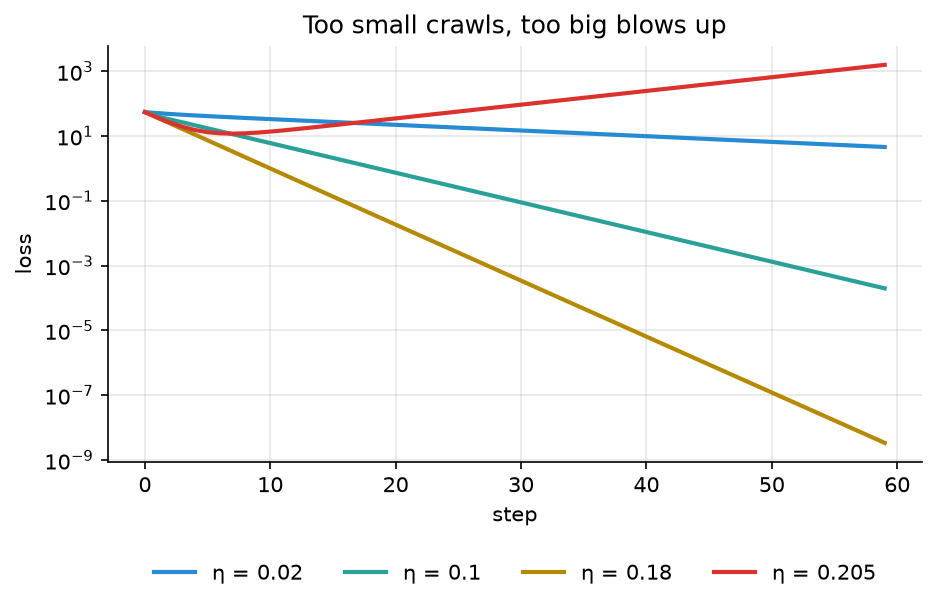

In [3]:
etas = [0.02, 0.1, 0.18, 0.205]
fig, ax = plt.subplots()
for eta, colour in zip(etas, COLOURS):
    ax.semilogy(descend(eta), color=colour, lw=2, label=f"η = {eta}")
ax.set_title("Too small crawls, too big blows up")
ax.set(xlabel="step", ylabel="loss")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.2))
plt.show()

With $L = 10$ the limit is $\eta = 0.2$. Just under it, at $0.18$, the steep direction
overshoots back and forth but still shrinks; just over it, at $0.205$, every step makes it
**worse**. The smallest step is safe and painfully slow.

In [4]:
def steps_to(eta, tol=1e-6):
    losses = descend(eta, steps=2000)
    below = np.flatnonzero(losses < tol)
    return int(below[0]) if below.size else None


rows = [
    {
        "step size η": round(eta, 3),
        "shrink per step": max(abs(1 - eta * lam) for lam in (1, 10)),
        "steps to 10⁻⁶": steps_to(eta) or "never",
    }
    for eta in [0.02, 0.1, 0.15, 2 / 11, 0.195, 0.205]
]
pd.DataFrame(rows).round(3)

,step size η,shrink per step,steps to 10⁻⁶
0,0.020,0.980,439
1,0.100,0.900,85
2,0.150,0.850,55
3,0.182,0.818,45
4,0.195,0.950,151
5,0.205,1.050,never


## In short

The best step, $\eta^\ast = 2/11 \approx 0.18$, balances the two directions: both shrink by
the same factor, $\tfrac{L - \mu}{L + \mu} \approx 0.82$, each step.

```mermaid
flowchart LR
    A[Pick a step size η] --> B{"η < 2/L ?"}
    B -->|no| C[Diverges]
    B -->|yes| D[Converges]
    D --> E["fastest at η = 2/(μ+L)"]
```

When the curvatures are far apart, no single step suits both, which is what momentum and
adaptive methods are for.